<a href="https://colab.research.google.com/github/ahmedmohamedshams233s-max/portfolio/blob/main/CXR_Report_Generation_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip -q install -U timm kaggle gradio

In [3]:
import os, re, json, time, math, random, copy, gc, collections, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tvm
from torchvision.transforms import v2
import timm
from IPython.display import display
warnings.filterwarnings('ignore')

# ----------------------------- switches -----------------------------
SMOKE_TEST  = False   # True = tiny run (500 studies, 1 epoch) just to test the pipeline
USE_DRIVE   = True    # True = save results/checkpoints to Google Drive (survives Colab disconnects). Raw data is NEVER put on Drive.
FORCE_RERUN = False   # True = ignore cached results and retrain everything

CFG = dict(SPLIT_SEED=42, IMG=224, MAX_LEN=60, MIN_FREQ=3, BATCH=32,
           EPOCHS=12, TUNE_EPOCHS=6, PATIENCE=4, SEEDS=[0, 1, 2],
           LR_GRID=[1e-4, 3e-4, 1e-3], D_MODEL=256, N_LAYERS=3, N_HEADS=8,
           WD=0.01, LABEL_SMOOTH=0.1, AUX_W=0.5, NO_REPEAT_N=4)
if SMOKE_TEST:
    CFG.update(EPOCHS=1, TUNE_EPOCHS=1, LR_GRID=[3e-4])

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
HW = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'
print('Device:', HW)
if DEVICE == 'cpu':
    print('WARNING: no GPU found. Runtime -> Change runtime type -> T4 GPU')

ROOT = Path('/content/cxr_report_project')
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        ROOT = Path('/content/drive/MyDrive/cxr_report_project')
    except Exception as e:
        print('Drive not mounted ->', e)
RES, CKPT, DATA_DIR = ROOT / 'experiments', ROOT / 'checkpoints', Path('/content/data')   # raw data stays on the Colab VM disk
for p in (RES, CKPT, DATA_DIR): p.mkdir(parents=True, exist_ok=True)
print('Results/checkpoints ->', ROOT)

S, MAX_LEN, SEEDS = CFG['IMG'], CFG['MAX_LEN'], CFG['SEEDS']
TABLES = {}   # every report table is stored here and exported at the end

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(0)

Device: Tesla T4
Drive not mounted -> Error: credential propagation was unsuccessful
Results/checkpoints -> /content/cxr_report_project


## 1. Problem Definition (Requirement 1)
**Task.** Automatic radiology report generation: given the chest X-ray study of a patient (frontal view, optionally + lateral view), generate the *findings* section of the radiology report.

**Input:** 1–2 chest X-ray images (224×224, grayscale→3ch). **Output:** a free-text report (≤ 60 words).

**Hypotheses we will test**
* **H1 – Pretraining helps.** On this small dataset (~3k studies), ImageNet-pretrained encoders beat the same architectures trained from scratch (both CNN and ViT).
* **H2 – Modern > classic.** A ViT encoder + Transformer decoder (M2) beats a CNN encoder + attention-LSTM decoder (M1).
* **H3 – Clinical guidance helps most for clinical metrics.** Adding the lateral view and an auxiliary disease-tag head (M3) improves *clinical-efficacy* F1 more than it improves n-gram metrics, compared with M2.
* **H4 – Augmentation helps.** Mild geometric/photometric augmentation improves generalisation on this small dataset.

**Metrics (task-appropriate, not accuracy):** BLEU-1..4, ROUGE-L (language quality) + **Clinical Efficacy (CE)** micro/macro-F1 and per-class F1 over 14 findings, extracted from generated vs. reference reports with a rule-based labeler (negation-aware).

## 2. Dataset Access (Requirement 2)
We use the public **IU X-Ray** dataset (Demner-Fushman et al., 2016) through its Kaggle mirror `raddar/chest-xrays-indiana-university`.
The data is downloaded **directly to the Colab VM** with your Kaggle API token — nothing is downloaded to your own machine.

**Token options (use one):**
1. *(Recommended)* Colab sidebar → 🔑 **Secrets** → add `KAGGLE_USERNAME` and `KAGGLE_KEY`, enable notebook access.
2. Paste them in the two variables below (don't commit them to GitHub!).
3. Leave both empty and you will be asked to type them securely.

In [4]:


from getpass import getpass
KAGGLE_USERNAME = ""   # <-- optional: paste here
KAGGLE_KEY      = ""   # <-- optional: paste here  (Kaggle -> Settings -> API -> Create New Token)

if not (KAGGLE_USERNAME and KAGGLE_KEY):
    try:
        from google.colab import userdata
        KAGGLE_USERNAME = userdata.get('KAGGLE_USERNAME'); KAGGLE_KEY = userdata.get('KAGGLE_KEY')
    except Exception:
        pass
already = any(DATA_DIR.rglob('indiana_reports.csv'))
if not already:
    if not (KAGGLE_USERNAME and KAGGLE_KEY):
        KAGGLE_USERNAME = input('Kaggle username: '); KAGGLE_KEY = getpass('Kaggle key/token: ')
    os.environ['KAGGLE_USERNAME'] = KAGGLE_USERNAME
    os.environ['KAGGLE_KEY'] = KAGGLE_KEY
    if KAGGLE_KEY.startswith('KGAT_'):          # new-style access token
        os.environ['KAGGLE_API_TOKEN'] = KAGGLE_KEY
    !kaggle datasets download -d raddar/chest-xrays-indiana-university -p {str(DATA_DIR)} --unzip
else:
    print('Dataset already on the VM.')
print([p.name for p in DATA_DIR.iterdir()])

Kaggle username: KGAT_a9bf6bb725fdc71742e58f96faa986d7
Kaggle key/token: ··········
Dataset URL: https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university
License(s): Attribution-NonCommercial-NoDerivatives 4.0 International (CC BY-NC-ND 4.0)
100% 13.2G/13.2G [02:38<00:00, 89.3MB/s]

['indiana_reports.csv', 'indiana_projections.csv', 'images']


## 3. Data Loading, Cleaning & Rule-based Findings Labeler
* One *study* = one report (`uid`) with a **frontal** image and (usually) a **lateral** image.
* Report text = `findings` (fallback to `impression` when findings is empty). Lower-casing, anonymisation tokens (`XXXX`) and numbers removed, tokens = words + periods.
* **Our own rule-based labeler** (negation-aware, sentence-level) extracts 14 finding labels from any text. It is used for (a) the auxiliary tag head of M3 and (b) the clinical-efficacy metric.

In [5]:
def find_file(name):
    hits = list(DATA_DIR.rglob(name)); assert hits, f'{name} not found under {DATA_DIR}'
    return hits[0]
rep = pd.read_csv(find_file('indiana_reports.csv'))
prj = pd.read_csv(find_file('indiana_projections.csv'))
IMG_DIR = [p for p in DATA_DIR.rglob('images_normalized') if p.is_dir()][0]
print('reports:', rep.shape, '| projections:', prj.shape, '| image dir:', IMG_DIR)

def clean(t):
    if not isinstance(t, str): return ''
    t = t.lower().replace('xxxx', ' ')
    t = re.sub(r'\d+(\.\d+)?', ' ', t)
    toks = re.findall(r"[a-z]+|\.", t)
    out = []
    for w in toks:
        if w == '.' and (not out or out[-1] == '.'): continue   # no leading / double periods
        out.append(w)
    return ' '.join(out)

fr = prj[prj.projection == 'Frontal'].drop_duplicates('uid')[['uid', 'filename']].rename(columns={'filename': 'frontal'})
la = prj[prj.projection == 'Lateral'].drop_duplicates('uid')[['uid', 'filename']].rename(columns={'filename': 'lateral'})
df = rep.merge(fr, on='uid', how='inner').merge(la, on='uid', how='left')

f_clean, i_clean = df.findings.map(clean), df.impression.map(clean)
df['text'] = [f if len(f.split()) >= 4 else i for f, i in zip(f_clean, i_clean)]
df = df[df.text.str.split().str.len() >= 4]
df = df[df.frontal.map(lambda f: (IMG_DIR / f).exists())].reset_index(drop=True)
df['ref'] = df.text.map(lambda t: ' '.join(t.split()[:MAX_LEN]))          # reference = truncated cleaned report
if SMOKE_TEST:
    df = df.sample(500, random_state=0).reset_index(drop=True)
print('studies kept:', len(df), '| with lateral view:', int(df.lateral.notna().sum()))
display(df[['uid', 'frontal', 'lateral', 'ref']].head(3))

reports: (3851, 8) | projections: (7466, 3) | image dir: /content/data/images/images_normalized
studies kept: 3666 | with lateral view: 3376


,uid,frontal,lateral,ref
0,1,1_IM-0001-4001.dcm.png,1_IM-0001-3001.dcm.png,the cardiac silhouette and mediastinum size ar...
1,2,2_IM-0652-1001.dcm.png,2_IM-0652-2001.dcm.png,borderline cardiomegaly . midline sternotomy ....
2,3,3_IM-1384-1001.dcm.png,3_IM-1384-2001.dcm.png,no displaced rib fractures pneumothorax or ple...


In [6]:
# ---------------- our own negation-aware rule-based labeler ----------------
PATTERNS = {
 'cardiomegaly':   r'cardiomegaly|enlarged heart|heart (size )?(is )?(mildly |moderately |markedly )?enlarged|cardiac silhouette (is )?(mildly |moderately |markedly )?enlarged',
 'effusion':       r'effusions?',
 'pneumothorax':   r'pneumothora(?:x|ces)',
 'pneumonia':      r'pneumonia|consolidation|infiltrates?',
 'atelectasis':    r'atelecta\w*',
 'edema':          r'edema',
 'opacity':        r'opacit(?:y|ies)|airspace disease|haziness',
 'nodule_mass':    r'nodul\w*|\bmass(?:es)?\b',
 'granuloma':      r'granulomas?|granulomatous|calcified',
 'emphysema_copd': r'emphysema|copd|hyperinflat\w*|hyperexpan\w*',
 'fracture':       r'fractures?',
 'spine_degen':    r'degenerative|spondylosis|scoliosis|osteophyt\w*',
 'device':         r'catheter|pacemaker|pacer|tube|stent|clips?|sternal wires?',
}
PAT = {k: re.compile(v) for k, v in PATTERNS.items()}
NEG_PRE  = re.compile(r'\b(no|without|negative|clear|free|absent|resolved|normal|not|neither|nor)\b')
NEG_POST = re.compile(r'\b(not|absent|resolved|excluded)\b')
CORE = ['cardiomegaly', 'effusion', 'pneumothorax', 'pneumonia', 'atelectasis', 'edema', 'opacity', 'nodule_mass', 'emphysema_copd', 'fracture']
LABELS = list(PATTERNS) + ['no_finding']
K = len(LABELS); CORE_IDX = [LABELS.index(c) for c in CORE]

def label_vec(text):
    v = np.zeros(K, np.float32)
    for sent in text.split('.'):
        for j, pat in enumerate(PAT.values()):
            for m in pat.finditer(sent):
                if not (NEG_PRE.search(sent[:m.start()]) or NEG_POST.search(sent[m.end():m.end() + 30])):
                    v[j] = 1; break
    v[-1] = float(v[CORE_IDX].sum() == 0)
    return v

for t in ['no pneumothorax or pleural effusion .', 'mild cardiomegaly with no effusion .', 'the lungs are clear .', 'small right pleural effusion .']:
    print(t, '->', [l for l, x in zip(LABELS, label_vec(t)) if x])
df['labels'] = [label_vec(t) for t in df.ref]

no pneumothorax or pleural effusion . -> ['no_finding']
mild cardiomegaly with no effusion . -> ['cardiomegaly']
the lungs are clear . -> ['no_finding']
small right pleural effusion . -> ['effusion']


## 4. Exploratory Analysis, Table 1, and a Leakage-free Split
**Split strategy:** random split by study (`uid`) → 70 % train / 10 % val / 20 % test, fixed seed. Both views of a study always stay in the same split, and we assert that no uid or image file is shared between splits. The vocabulary is built **from the training set only**. The test set is only touched in the final-evaluation stages (§10–§11).
*Limitation:* the public CSV has no patient ID, so a patient with several studies could in principle appear in two splits.

{'train': 2566, 'val': 366, 'test': 734} -> no uid/image overlap between splits OK


,Dataset,Source,Size,Format,Classes,Licence,Role
0,IU X-Ray (Open-i),Kaggle mirror raddar/chest-xrays-indiana-unive...,3666 studies / 7042 images,PNG (frontal + lateral) + CSV reports,free-text report; 14 rule-based finding labels,Open-i / NLM terms for research use (verify at...,train 2566 / val 366 / test 734


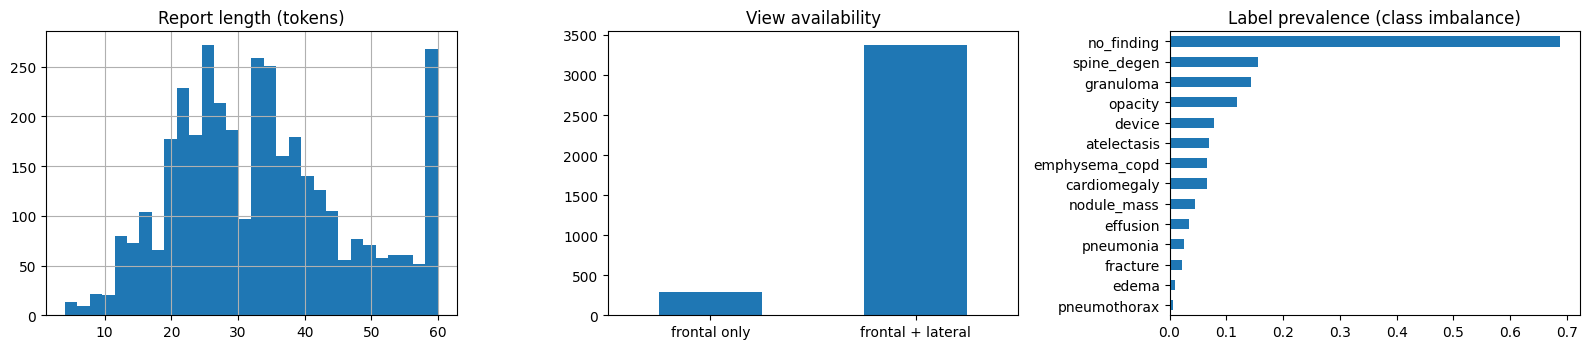

In [7]:
rng = np.random.RandomState(CFG['SPLIT_SEED'])
uids = df.uid.unique().copy(); rng.shuffle(uids)
n = len(uids); n_tr, n_va = int(.7 * n), int(.1 * n)
split_of = {u: 'train' for u in uids[:n_tr]}
split_of.update({u: 'val' for u in uids[n_tr:n_tr + n_va]}); split_of.update({u: 'test' for u in uids[n_tr + n_va:]})
df['split'] = df.uid.map(split_of)

# ---- leakage checks ----
parts = {s: df[df.split == s] for s in ['train', 'val', 'test']}
files = {s: set(d.frontal) | set(d.lateral.dropna()) for s, d in parts.items()}
assert not (set(parts['train'].uid) & set(parts['val'].uid)) and not (set(parts['train'].uid) & set(parts['test'].uid)) and not (set(parts['val'].uid) & set(parts['test'].uid))
assert not (files['train'] & files['val']) and not (files['train'] & files['test']) and not (files['val'] & files['test'])
print({s: len(d) for s, d in parts.items()}, '-> no uid/image overlap between splits OK')

# ---- Table 1: dataset comparison ----
t1 = pd.DataFrame([dict(Dataset='IU X-Ray (Open-i)', Source='Kaggle mirror raddar/chest-xrays-indiana-university (orig.: openi.nlm.nih.gov)',
    Size=f"{len(df)} studies / {len(files['train'])+len(files['val'])+len(files['test'])} images",
    Format='PNG (frontal + lateral) + CSV reports', Classes='free-text report; 14 rule-based finding labels',
    Licence='Open-i / NLM terms for research use (verify at source)',
    Role=f"train {len(parts['train'])} / val {len(parts['val'])} / test {len(parts['test'])}")])
TABLES['table1_dataset'] = t1; display(t1)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
df.ref.str.split().str.len().hist(bins=30, ax=ax[0]); ax[0].set_title('Report length (tokens)')
pd.Series({'frontal only': int(df.lateral.isna().sum()), 'frontal + lateral': int(df.lateral.notna().sum())}).plot.bar(ax=ax[1], rot=0); ax[1].set_title('View availability')
prev = pd.Series(np.stack(df.labels).mean(0), index=LABELS).sort_values(); prev.plot.barh(ax=ax[2]); ax[2].set_title('Label prevalence (class imbalance)')
plt.tight_layout(); plt.show()

vocab size: 810
image cache: (7042, 224, 224) 337 MB


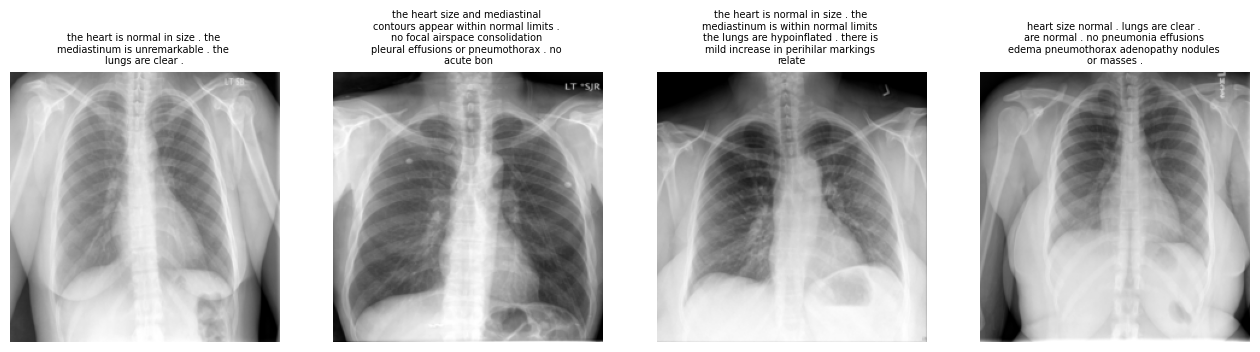

In [8]:
# ---- tokenizer (vocabulary from TRAIN only) ----
class Tokenizer:
    PAD, BOS, EOS, UNK = 0, 1, 2, 3
    def __init__(self, texts, min_freq):
        c = collections.Counter(w for t in texts for w in t.split())
        self.itos = ['<pad>', '<bos>', '<eos>', '<unk>'] + [w for w, k in c.most_common() if k >= min_freq]
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def encode(self, t, max_len):
        return [1] + [self.stoi.get(w, 3) for w in t.split()][:max_len] + [2]
    def decode(self, ids):
        out = []
        for i in ids:
            i = int(i)
            if i in (0, 2): break
            if i > 3: out.append(self.itos[i])
        return ' '.join(out)
tok = Tokenizer(parts['train'].ref.tolist(), CFG['MIN_FREQ']); V = len(tok.itos)
print('vocab size:', V)

# ---- cache all images once in RAM as uint8 (N, S, S) ----
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
all_files = sorted(set(df.frontal) | set(df.lateral.dropna()))
def _load(f): return np.array(Image.open(IMG_DIR / f).convert('L').resize((S, S), Image.BILINEAR), dtype=np.uint8)
with ThreadPoolExecutor(8) as ex: arrs = list(ex.map(_load, all_files))
IMGS = torch.from_numpy(np.stack(arrs)); F2I = {f: i for i, f in enumerate(all_files)}
print('image cache:', tuple(IMGS.shape), f'{IMGS.numel()/2**20:.0f} MB')

# ---- sample images + reports ----
fig, ax = plt.subplots(1, 4, figsize=(16, 4.5))
for a, (_, r) in zip(ax, df.sample(4, random_state=1).iterrows()):
    a.imshow(IMGS[F2I[r.frontal]], cmap='gray'); a.axis('off'); a.set_title('\n'.join(re.findall(r'.{1,38}(?:\s|$)', r.ref[:150])), fontsize=7)
plt.show()

In [9]:
# ---------------------------- Dataset / DataLoader ----------------------------
AUG = v2.Compose([v2.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                  v2.ColorJitter(brightness=0.2, contrast=0.2)])      # no horizontal flip: laterality (left/right) matters in radiology
class CXRDataset(Dataset):
    def __init__(self, d, augment=False):
        self.f, self.l = d.frontal.tolist(), d.lateral.tolist()
        self.ids = [tok.encode(t, MAX_LEN) for t in d.ref]
        self.y = np.stack(d.labels.tolist()).astype(np.float32); self.aug = augment
    def _img(self, name):
        x = IMGS[F2I[name]].unsqueeze(0).expand(3, -1, -1).contiguous()
        return AUG(x) if self.aug else x
    def __len__(self): return len(self.f)
    def __getitem__(self, i):
        f = self._img(self.f[i]); has = isinstance(self.l[i], str)
        l = self._img(self.l[i]) if has else f.clone()
        return f, l, float(has), torch.tensor(self.ids[i]), torch.from_numpy(self.y[i]), i

def collate(b):
    f, l, h, t, y, i = zip(*b); T = torch.zeros(len(b), max(len(x) for x in t), dtype=torch.long)
    for k, x in enumerate(t): T[k, :len(x)] = x
    return torch.stack(f), torch.stack(l), torch.tensor(h), T, torch.stack(y), torch.tensor(i)

def make_loader(ds, shuffle, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=CFG['BATCH'], shuffle=shuffle, collate_fn=collate, num_workers=2, pin_memory=(DEVICE == 'cuda'), generator=g)

DS = {'train': CXRDataset(parts['train'].reset_index(drop=True), False), 'train_aug': CXRDataset(parts['train'].reset_index(drop=True), True),
      'val': CXRDataset(parts['val'].reset_index(drop=True)), 'test': CXRDataset(parts['test'].reset_index(drop=True))}
REFS = {s: parts[s].ref.tolist() for s in ['train', 'val', 'test']}
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(DEVICE), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(DEVICE)
def prep(batch):
    f, l, h, T, y, i = batch
    norm = lambda x: (x.to(DEVICE, non_blocking=True).float() / 255 - MEAN) / STD
    return dict(f=norm(f), l=norm(l), has_l=h.to(DEVICE), tokens=T.to(DEVICE), labels=y.to(DEVICE), idx=i)
print({k: len(v) for k, v in DS.items()})

{'train': 2566, 'train_aug': 2566, 'val': 366, 'test': 734}


## 5. Evaluation Metrics (shared by *all* models — `evaluate.py` equivalent)
* **BLEU-1..4** (NLTK, smoothing method 1 — Chen & Cherry 2014), **ROUGE-L** (our own LCS implementation).
* **Clinical Efficacy (CE):** run our labeler on generated and reference reports → micro/macro F1 and **per-class precision/recall/F1** over the 14 labels.
* `composite` = mean(BLEU-4, ROUGE-L, CE micro-F1) → used **only** for model selection on the *validation* set.
* Seed variance: mean ± SD over 3 seeds. Bootstrap 95 % CI on the test set (§13).

In [10]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from sklearn.metrics import precision_recall_fscore_support
SM = SmoothingFunction().method1

def lcs(a, b):
    if not a or not b: return 0
    prev = [0] * (len(b) + 1)
    for x in a:
        cur = [0]
        for j, y in enumerate(b): cur.append(prev[j] + 1 if x == y else max(prev[j + 1], cur[j]))
        prev = cur
    return prev[-1]
def rouge_l(ref, hyp):
    r, h = ref.split(), hyp.split(); l = lcs(r, h)
    if l == 0: return 0.0
    p, rc = l / len(h), l / len(r); return 2 * p * rc / (p + rc)

def bleu_all(refs, hyps):
    if all(len(h.split()) == 0 for h in hyps): return [0.0] * 4
    R, H = [[r.split()] for r in refs], [h.split() for h in hyps]
    return [float(corpus_bleu(R, H, weights=w, smoothing_function=SM)) for w in [(1, 0, 0, 0), (.5, .5, 0, 0), (1/3, 1/3, 1/3, 0), (.25, .25, .25, .25)]]

def compute_metrics(refs, hyps):
    b = bleu_all(refs, hyps); rl = float(np.mean([rouge_l(r, h) for r, h in zip(refs, hyps)]))
    Y = np.stack([label_vec(t) for t in refs]); P = np.stack([label_vec(t) for t in hyps])
    p, r, f, s = precision_recall_fscore_support(Y, P, average=None, zero_division=0)
    micro = float(precision_recall_fscore_support(Y, P, average='micro', zero_division=0)[2]); sup = Y.sum(0)
    macro = float(f[sup > 0].mean())
    return dict(bleu1=b[0], bleu2=b[1], bleu3=b[2], bleu4=b[3], rougeL=rl, ce_micro_f1=micro, ce_macro_f1=macro,
                composite=float(np.mean([b[3], rl, micro])), avg_len=float(np.mean([len(h.split()) for h in hyps])),
                per_class={LABELS[k]: dict(p=float(p[k]), r=float(r[k]), f1=float(f[k]), support=int(sup[k])) for k in range(K)})
print('metrics OK (reference vs itself):', {k: round(v, 3) for k, v in compute_metrics(REFS['val'][:50], REFS['val'][:50]).items() if k != 'per_class'})

metrics OK (reference vs itself): {'bleu1': 1.0, 'bleu2': 1.0, 'bleu3': 1.0, 'bleu4': 1.0, 'rougeL': 1.0, 'ce_micro_f1': 1.0, 'ce_macro_f1': 1.0, 'composite': 1.0, 'avg_len': 35.1}


## 6. Baselines — classical ML (Requirement 3)
* **B0 – Generic report:** one fixed "best average" training report for every image.
* **B1 – kNN retrieval (classical ML):** 32×32 downsampled pixels → StandardScaler → PCA(50) → 1-nearest-neighbour in the training set → copy that report. Deterministic (no seed variance).
Baselines are evaluated on validation and test with exactly the same metrics.

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
tr = parts['train'].reset_index(drop=True)

def img_feats(d):
    x = IMGS[[F2I[f] for f in d.frontal]].float().unsqueeze(1) / 255
    return F.adaptive_avg_pool2d(x, 32).flatten(1).numpy()

# B0: generic report (best mean ROUGE-L against a sample of training reports)
t0 = time.time(); r0 = np.random.RandomState(0)
cands = r0.choice(len(tr), min(60, len(tr)), replace=False); refs_s = r0.choice(len(tr), min(150, len(tr)), replace=False)
scores = [np.mean([rouge_l(tr.ref[j], tr.ref[c]) for j in refs_s]) for c in cands]
GENERIC = tr.ref[cands[int(np.argmax(scores))]]; t_b0 = time.time() - t0
print('B0 generic report:', GENERIC)

# B1: kNN retrieval
t0 = time.time()
sc = StandardScaler().fit(img_feats(tr)); pca = PCA(50, random_state=0).fit(sc.transform(img_feats(tr)))
nn_ = NearestNeighbors(n_neighbors=1, metric='cosine').fit(pca.transform(sc.transform(img_feats(tr)))); t_b1 = time.time() - t0
def knn_predict(d):
    _, ix = nn_.kneighbors(pca.transform(sc.transform(img_feats(d)))); return [tr.ref[i] for i in ix[:, 0]]

BASE = {}
for name, fn in [('B0 Generic report', lambda d: [GENERIC] * len(d)), ('B1 kNN retrieval (PCA)', knn_predict)]:
    BASE[name] = {}
    for sp in ['val', 'test']:
        t0 = time.time(); hyps = fn(parts[sp]); dt = time.time() - t0
        BASE[name][sp] = compute_metrics(REFS[sp], hyps); BASE[name][sp]['infer_ms'] = 1000 * dt / len(hyps)
        if sp == 'test': BASE[name]['hyps'] = hyps
    BASE[name]['fit_s'] = t_b0 if name.startswith('B0') else t_b1
show = pd.DataFrame({k: {m: round(v['test'][m], 3) for m in ['bleu1', 'bleu4', 'rougeL', 'ce_micro_f1', 'ce_macro_f1', 'composite']} for k, v in BASE.items()}).T
display(show)

B0 generic report: the heart is normal in size and contour . there is no mediastinal widening . the lungs are clear bilaterally . no pleural effusion or pneumothorax . are intact .


,bleu1,bleu4,rougeL,ce_micro_f1,ce_macro_f1,composite
B0 Generic report,0.471,0.145,0.369,0.540,0.058,0.351
B1 kNN retrieval (PCA),0.374,0.092,0.280,0.386,0.116,0.252


## 7. Deep-learning Models (Requirement 4 & 5)
All three models share the **same decoding procedure** (our own greedy decoder with no-repeat-4-gram blocking), loss (cross-entropy with label smoothing 0.1), optimizer and data pipeline.

| | Category | Encoder | Decoder | Extra |
|---|---|---|---|---|
| **M1** | Classic | ResNet-18 (ImageNet-pretrained) → 7×7 grid | LSTM + **Bahdanau attention** (own) | – |
| **M2** | Modern | ViT-Small/16 (pretrained, timm) | **Transformer decoder (own: MHA, masked self-attn, cross-attn, FFN)** | – |
| **M3** | Advanced | same ViT, **frontal + lateral** with view embeddings | same Transformer decoder | **Auxiliary disease-tag head** (BCE) whose probabilities become *tag tokens* the decoder cross-attends to |

*Components written by us (not from a library):* multi-head attention, decoder layer/Transformer decoder, Bahdanau attention, LSTM decoding loop, tag-token module, greedy decoder with n-gram blocking, ROUGE-L, rule-based labeler.

In [12]:
# ----------------------- shared: our own greedy decoder -----------------------
@torch.no_grad()
def greedy_decode(step_fn, B, max_len, block_n=CFG['NO_REPEAT_N']):
    ys = torch.full((B, 1), 1, dtype=torch.long, device=DEVICE); done = torch.zeros(B, dtype=torch.bool, device=DEVICE)
    for _ in range(max_len):
        lg = step_fn(ys).float(); lg[:, 0] = lg[:, 1] = lg[:, 3] = -1e9          # never emit <pad>/<bos>/<unk>
        if block_n and ys.size(1) >= block_n:                                     # no-repeat n-gram blocking
            seqs, dl = ys.tolist(), done.tolist()
            for i, sq in enumerate(seqs):
                if dl[i]: continue
                pref = tuple(sq[-(block_n - 1):])
                for j in range(len(sq) - block_n + 1):
                    if tuple(sq[j:j + block_n - 1]) == pref: lg[i, sq[j + block_n - 1]] = -1e9
        nxt = torch.where(done, torch.zeros_like(lg.argmax(-1)), lg.argmax(-1))
        ys = torch.cat([ys, nxt[:, None]], 1); done |= nxt == 2
        if done.all(): break
    return ys[:, 1:]

# ----------------------- our own attention + Transformer decoder -----------------------
class MHA(nn.Module):
    def __init__(self, d, h, drop=0.1):
        super().__init__(); self.h, self.drop = h, drop
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))
    def forward(self, x, kv, causal=False, kv_mask=None):
        B, Lq, _ = x.shape; Lk = kv.size(1)
        q = self.q(x).view(B, Lq, self.h, -1).transpose(1, 2); k = self.k(kv).view(B, Lk, self.h, -1).transpose(1, 2)
        v = self.v(kv).view(B, Lk, self.h, -1).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(q.size(-1))                       # scaled dot-product
        if causal: att = att.masked_fill(torch.triu(torch.ones(Lq, Lk, dtype=torch.bool, device=x.device), 1), float('-inf'))
        if kv_mask is not None: att = att.masked_fill(~kv_mask[:, None, None, :], float('-inf'))
        att = F.dropout(att.softmax(-1), self.drop, self.training)
        return self.o((att @ v).transpose(1, 2).reshape(B, Lq, -1))

class DecLayer(nn.Module):
    def __init__(self, d, h, ff, drop):
        super().__init__(); self.n1, self.n2, self.n3 = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d)
        self.sa, self.ca = MHA(d, h, drop), MHA(d, h, drop)
        self.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Dropout(drop), nn.Linear(ff, d)); self.dr = nn.Dropout(drop)
    def forward(self, x, mem, mm):
        h = self.n1(x); x = x + self.dr(self.sa(h, h, causal=True))                   # masked self-attention
        x = x + self.dr(self.ca(self.n2(x), mem, kv_mask=mm))                         # cross-attention to image tokens
        return x + self.dr(self.ff(self.n3(x)))

class TDecoder(nn.Module):
    def __init__(self, V, d, h, L, drop=0.1, maxpos=128):
        super().__init__(); self.d = d
        self.emb, self.pos = nn.Embedding(V, d, padding_idx=0), nn.Embedding(maxpos, d)
        self.layers = nn.ModuleList([DecLayer(d, h, 4 * d, drop) for _ in range(L)]); self.ln = nn.LayerNorm(d); self.out = nn.Linear(d, V); self.dr = nn.Dropout(drop)
    def forward(self, tokens, mem, mm=None):
        x = self.dr(self.emb(tokens) * math.sqrt(self.d) + self.pos(torch.arange(tokens.size(1), device=tokens.device)))
        for l in self.layers: x = l(x, mem, mm)
        return self.out(self.ln(x))

def lm_loss(logits, target):
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), target.reshape(-1), ignore_index=0, label_smoothing=CFG['LABEL_SMOOTH'])

In [13]:
# ------------------------------- M1: CNN + attention-LSTM (classic) -------------------------------
class CNNLSTM(nn.Module):
    def __init__(self, V, pretrained=True, emb=256, hid=512, drop=0.3):
        super().__init__()
        r = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        self.enc = nn.Sequential(*list(r.children())[:-2]); D = 512
        self.emb = nn.Embedding(V, emb, padding_idx=0)
        self.att_e, self.att_h, self.att_v = nn.Linear(D, hid), nn.Linear(hid, hid), nn.Linear(hid, 1)   # Bahdanau (additive) attention
        self.init_h, self.init_c = nn.Linear(D, hid), nn.Linear(D, hid)
        self.cell = nn.LSTMCell(emb + D, hid); self.drop = nn.Dropout(drop); self.out = nn.Linear(hid, V)
    def encoder_params(self): return self.enc.parameters()
    def encode(self, f): return self.enc(f).flatten(2).transpose(1, 2)               # (B, 49, 512)
    def init_state(self, feats):
        m = feats.mean(1); return torch.tanh(self.init_h(m)), torch.tanh(self.init_c(m))
    def step(self, tok, feats, st):
        h, c = st
        a = self.att_v(torch.tanh(self.att_e(feats) + self.att_h(h).unsqueeze(1))).squeeze(-1).softmax(-1)
        ctx = (a.unsqueeze(-1) * feats).sum(1)
        h, c = self.cell(torch.cat([self.emb(tok), ctx], -1), (h, c)); return self.out(self.drop(h)), (h, c)
    def loss(self, b):
        feats = self.encode(b['f']); st = self.init_state(feats); T = b['tokens']; lgs = []
        for t in range(T.size(1) - 1):
            lg, st = self.step(T[:, t], feats, st); lgs.append(lg)
        l = lm_loss(torch.stack(lgs, 1), T[:, 1:]); return l, {'lm': l.item()}
    @torch.no_grad()
    def generate(self, b, max_len):
        feats = self.encode(b['f']); st = [self.init_state(feats)]
        def fn(ys):
            lg, st[0] = self.step(ys[:, -1], feats, st[0]); return lg
        return greedy_decode(fn, feats.size(0), max_len)

# ----------------- M2 (modern) and M3 (advanced): ViT encoder + our Transformer decoder -----------------
class ReportTransformer(nn.Module):
    def __init__(self, V, pretrained=True, multiview=False, use_tags=False, K=K, d=CFG['D_MODEL'], L=CFG['N_LAYERS'], h=CFG['N_HEADS'], drop=0.1):
        super().__init__(); self.multiview, self.use_tags = multiview, use_tags
        self.vit = timm.create_model('vit_small_patch16_224', pretrained=pretrained, num_classes=0); D = self.vit.num_features
        self.proj = nn.Sequential(nn.Linear(D, d), nn.LayerNorm(d))
        self.view_emb = nn.Parameter(torch.randn(2, 1, d) * 0.02)
        if use_tags:
            self.tag_head = nn.Linear(D, K)                                           # auxiliary multi-label disease-tag classifier
            self.tag_emb = nn.Parameter(torch.randn(K, 2, d))                         # per-tag embeddings: [present, absent]
        self.dec = TDecoder(V, d, h, L, drop)
    def encoder_params(self): return self.vit.parameters()
    def memory(self, b):
        zf = self.vit.forward_features(b['f']); mem = [self.proj(zf) + self.view_emb[0]]
        mask = [torch.ones(mem[0].shape[:2], dtype=torch.bool, device=zf.device)]; pooled = zf.mean(1)
        if self.multiview:
            zl = self.vit.forward_features(b['l']); ml = self.proj(zl) + self.view_emb[1]; hasl = b['has_l'] > 0.5
            mem.append(ml); mask.append(hasl[:, None].expand(-1, ml.size(1)))
            w = hasl.float()[:, None]; pooled = (zf.mean(1) + zl.mean(1) * w) / (1 + w)
        logits = None
        if self.use_tags:
            logits = self.tag_head(pooled); p = torch.sigmoid(logits.float())[..., None]
            tt = p * self.tag_emb[:, 0] + (1 - p) * self.tag_emb[:, 1]               # (B, K, d) tag tokens
            mem.append(tt.to(mem[0].dtype)); mask.append(torch.ones(tt.shape[:2], dtype=torch.bool, device=tt.device))
        return torch.cat(mem, 1), torch.cat(mask, 1), logits
    def loss(self, b):
        mem, mask, logits = self.memory(b); T = b['tokens']
        l = lm_loss(self.dec(T[:, :-1], mem, mask), T[:, 1:]); info = {'lm': l.item()}
        if logits is not None:
            aux = F.binary_cross_entropy_with_logits(logits.float(), b['labels']); l = l + CFG['AUX_W'] * aux; info['aux'] = aux.item()
        return l, info
    @torch.no_grad()
    def generate(self, b, max_len):
        mem, mask, _ = self.memory(b)
        return greedy_decode(lambda ys: self.dec(ys, mem, mask)[:, -1], mem.size(0), max_len)

SPECS = {
 'M1':        dict(kind='cnn_lstm', pretrained=True,  augment=True),
 'M2':        dict(kind='vit_tf',   pretrained=True,  augment=True),
 'M3':        dict(kind='vit_tf',   pretrained=True,  augment=True, multiview=True,  use_tags=True),
 # ----- studies / ablations (§11) -----
 'M2_noaug':  dict(kind='vit_tf',   pretrained=True,  augment=False),
 'M1_scratch':dict(kind='cnn_lstm', pretrained=False, augment=True),
 'M2_scratch':dict(kind='vit_tf',   pretrained=False, augment=True),
 'M3_nolat':  dict(kind='vit_tf',   pretrained=True,  augment=True, multiview=False, use_tags=True),
 'M3_notags': dict(kind='vit_tf',   pretrained=True,  augment=True, multiview=True,  use_tags=False),
}
NICE = {'M1': 'M1 CNN-LSTM (classic)', 'M2': 'M2 ViT-Transformer (modern)', 'M3': 'M3 Multi-view Tag-guided (advanced)'}
def build_model(spec):
    if spec['kind'] == 'cnn_lstm': return CNNLSTM(V, pretrained=spec['pretrained'])
    return ReportTransformer(V, pretrained=spec['pretrained'], multiview=spec.get('multiview', False), use_tags=spec.get('use_tags', False))
for k in ['M1', 'M2', 'M3']:
    m = build_model(SPECS[k]); print(k, f'{sum(p.numel() for p in m.parameters())/1e6:.1f}M params'); del m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


M1 15.5M params


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

M2 25.4M params
M3 25.4M params


## 8. Training Engine (one function used by *every* experiment → fair comparison)
Same split, preprocessing, optimizer (AdamW, wd 0.01, warm-up + cosine schedule), mixed precision, gradient clipping, early stopping on validation loss, and decoding for all models.
Pretrained encoders use 0.3× the learning rate of the decoder. Every run is cached as JSON (so a Colab disconnect never loses finished runs) and the test set can **never** be used while tuning (`assert`).

In [14]:
AC = lambda: torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == 'cuda'))

@torch.no_grad()
def eval_loss(model, loader):
    model.eval(); tot = n = 0
    for batch in loader:
        b = prep(batch)
        with AC(): l, _ = model.loss(b)
        tot += l.item() * len(b['idx']); n += len(b['idx'])
    return tot / n

@torch.no_grad()
def generate_all(model, loader):
    model.eval(); hyps = []
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for batch in loader:
        b = prep(batch)
        with AC(): ids = model.generate(b, MAX_LEN + 1)
        hyps += [tok.decode(s) for s in ids.cpu()]
    if DEVICE == 'cuda': torch.cuda.synchronize()
    return hyps, time.time() - t0

def run_exp(name, spec, seed, lr, epochs, splits=('val',), stage='final', save_ckpt=False):
    if stage == 'tune': assert tuple(splits) == ('val',), 'the test set must NOT be used while tuning'
    fn = RES / f"run__{name}__s{seed}__lr{lr:g}__e{epochs}.json"
    if fn.exists() and not FORCE_RERUN: return json.load(open(fn))
    set_seed(seed)
    tl = make_loader(DS['train_aug' if spec['augment'] else 'train'], True, seed); vl = make_loader(DS['val'], False)
    model = build_model(spec).to(DEVICE); params = sum(p.numel() for p in model.parameters())
    enc_ids = {id(p) for p in model.encoder_params()}
    enc = [p for p in model.parameters() if id(p) in enc_ids]; rest = [p for p in model.parameters() if id(p) not in enc_ids]
    opt = torch.optim.AdamW([{'params': enc, 'lr': lr * 0.3 if spec['pretrained'] else lr}, {'params': rest, 'lr': lr}], weight_decay=CFG['WD'])
    total = epochs * len(tl); warm = max(1, int(0.05 * total))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))
    if DEVICE == 'cuda': torch.cuda.reset_peak_memory_stats()
    best, best_state, bad, hist, t_train = 1e9, None, 0, [], 0.0
    for ep in range(epochs):
        model.train(); t0 = time.time(); run = cnt = 0
        for batch in tl:
            b = prep(batch); opt.zero_grad(set_to_none=True)
            with AC(): loss, _ = model.loss(b)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); run += loss.item() * len(b['idx']); cnt += len(b['idx'])
        if DEVICE == 'cuda': torch.cuda.synchronize()
        t_train += time.time() - t0; vloss = eval_loss(model, vl); hist.append(dict(epoch=ep + 1, train_loss=run / cnt, val_loss=vloss))
        print(f'  [{name} s{seed} lr{lr:g}] ep {ep+1}/{epochs} train {run/cnt:.3f} val {vloss:.3f} ({time.time()-t0:.0f}s)')
        if vloss < best - 1e-4: best, bad, best_state = vloss, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['PATIENCE']: print('  early stop'); break
    peak = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == 'cuda' else 0.0
    model.load_state_dict(best_state)
    res = dict(name=name, spec=spec, seed=seed, lr=lr, epochs=epochs, epochs_run=len(hist), stage=stage, history=hist, best_val_loss=best,
               train_time_s=t_train, params=params, peak_mem_mb=peak, hardware=HW, file=str(fn), preds={})
    for sp in splits:
        hyps, dt = generate_all(model, make_loader(DS[sp], False))
        res[f'metrics_{sp}'] = compute_metrics(REFS[sp], hyps); res[f'infer_ms_{sp}'] = 1000 * dt / len(hyps)
        pf = RES / f"pred__{name}__s{seed}__lr{lr:g}__e{epochs}__{sp}.json"; json.dump(hyps, open(pf, 'w')); res['preds'][sp] = str(pf)
    if save_ckpt:
        ck = CKPT / f'{name}__s{seed}.pt'; torch.save(best_state, ck); res['ckpt'] = str(ck); res['ckpt_mb'] = ck.stat().st_size / 2**20
    json.dump(res, open(fn, 'w')); del model, opt; gc.collect(); torch.cuda.empty_cache()
    r = res.get('metrics_test', res['metrics_val']); print(f"  -> done: composite {r['composite']:.3f} | bleu4 {r['bleu4']:.3f} | rougeL {r['rougeL']:.3f} | CE-F1 {r['ce_micro_f1']:.3f}")
    return res

## 9. Hyper-parameter Study (Requirement 7a) — same budget for every model
Every model gets **exactly the same budget**: learning rate ∈ {1e-4, 3e-4, 1e-3}, one seed, `TUNE_EPOCHS` epochs, evaluated on the **validation set only**. The best learning rate (by validation composite score) is then used for the final runs.

  [M1 s0 lr0.0001] ep 1/6 train 5.545 val 4.709 (28s)
  [M1 s0 lr0.0001] ep 2/6 train 4.469 val 4.088 (25s)
  [M1 s0 lr0.0001] ep 3/6 train 3.984 val 3.765 (25s)
  [M1 s0 lr0.0001] ep 4/6 train 3.756 val 3.628 (25s)
  [M1 s0 lr0.0001] ep 5/6 train 3.663 val 3.581 (25s)
  [M1 s0 lr0.0001] ep 6/6 train 3.635 val 3.574 (25s)
  -> done: composite 0.348 | bleu4 0.135 | rougeL 0.362 | CE-F1 0.546
  [M1 s0 lr0.0003] ep 1/6 train 5.090 val 4.070 (25s)
  [M1 s0 lr0.0003] ep 2/6 train 3.707 val 3.340 (25s)
  [M1 s0 lr0.0003] ep 3/6 train 3.270 val 3.113 (25s)
  [M1 s0 lr0.0003] ep 4/6 train 3.097 val 3.011 (25s)
  [M1 s0 lr0.0003] ep 5/6 train 3.020 val 2.971 (26s)
  [M1 s0 lr0.0003] ep 6/6 train 2.993 val 2.965 (25s)
  -> done: composite 0.310 | bleu4 0.067 | rougeL 0.317 | CE-F1 0.546
  [M1 s0 lr0.001] ep 1/6 train 4.531 val 3.317 (25s)
  [M1 s0 lr0.001] ep 2/6 train 3.073 val 2.814 (25s)
  [M1 s0 lr0.001] ep 3/6 train 2.747 val 2.644 (25s)
  [M1 s0 lr0.001] ep 4/6 train 2.592 val 2.567 (25s)


,Model,LR,val_loss,BLEU4,ROUGE_L,CE_F1,composite
0,M1,0.0001,3.5736,0.1349,0.3618,0.5458,0.3475
1,M1,0.0003,2.9650,0.0669,0.3174,0.5458,0.3101
2,M1,0.0010,2.5309,0.0666,0.3168,0.5458,0.3098
3,M2,0.0001,3.6684,0.0713,0.3333,0.5458,0.3168
4,M2,0.0003,3.0849,0.0360,0.3037,0.5458,0.2952
5,M2,0.0010,2.6848,0.0666,0.3168,0.5458,0.3098
6,M3,0.0001,3.7067,0.0271,0.2977,0.5458,0.2902
7,M3,0.0003,3.1419,0.0942,0.3746,0.5458,0.3382
8,M3,0.0010,2.7773,0.0666,0.3168,0.5458,0.3098


Best LR per model: {'M1': 0.0001, 'M2': 0.0001, 'M3': 0.0003}


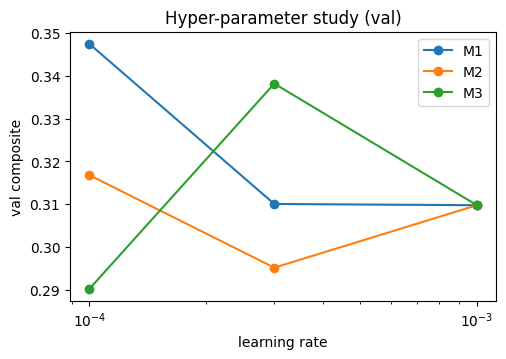

In [15]:
BEST_LR, tune_rows = {}, []
for k in ['M1', 'M2', 'M3']:
    for lr in CFG['LR_GRID']:
        r = run_exp(k, SPECS[k], 0, lr, CFG['TUNE_EPOCHS'], ('val',), stage='tune')
        m = r['metrics_val']; tune_rows.append(dict(Model=k, LR=lr, val_loss=r['best_val_loss'], BLEU4=m['bleu4'], ROUGE_L=m['rougeL'], CE_F1=m['ce_micro_f1'], composite=m['composite']))
tune = pd.DataFrame(tune_rows)
for k in ['M1', 'M2', 'M3']: BEST_LR[k] = float(tune[tune.Model == k].sort_values('composite').iloc[-1].LR)
TABLES['hyperparam_study_val'] = tune; display(tune.round(4)); print('Best LR per model:', BEST_LR)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for k in ['M1', 'M2', 'M3']: d = tune[tune.Model == k]; ax.plot(d.LR, d.composite, 'o-', label=k)
ax.set_xscale('log'); ax.set_xlabel('learning rate'); ax.set_ylabel('val composite'); ax.legend(); ax.set_title('Hyper-parameter study (val)'); plt.show()
BEST_LR.update({'M2_noaug': BEST_LR['M2'], 'M2_scratch': BEST_LR['M2'], 'M1_scratch': BEST_LR['M1'], 'M3_nolat': BEST_LR['M3'], 'M3_notags': BEST_LR['M3']})

## 10. Final Training — 3 Seeds per Model (Requirement 6)
Best LR per model, `EPOCHS` epochs, seeds 0/1/2 (seed changes weight-init, dropout, data order, augmentation; the data split is fixed). Validation **and** test are evaluated here. The test set is used only for reporting, never for selection.

In [16]:
for k in ['M1', 'M2', 'M3']:
    for s in SEEDS:
        run_exp(k, SPECS[k], s, BEST_LR[k], CFG['EPOCHS'], ('val', 'test'), stage='final', save_ckpt=(s == 0))
print('final runs done')

  [M1 s0 lr0.0001] ep 1/12 train 5.751 val 4.773 (30s)
  [M1 s0 lr0.0001] ep 2/12 train 4.517 val 4.097 (26s)
  [M1 s0 lr0.0001] ep 3/12 train 3.948 val 3.688 (28s)
  [M1 s0 lr0.0001] ep 4/12 train 3.632 val 3.461 (26s)
  [M1 s0 lr0.0001] ep 5/12 train 3.449 val 3.325 (26s)
  [M1 s0 lr0.0001] ep 6/12 train 3.331 val 3.239 (26s)
  [M1 s0 lr0.0001] ep 7/12 train 3.258 val 3.180 (26s)
  [M1 s0 lr0.0001] ep 8/12 train 3.206 val 3.142 (25s)
  [M1 s0 lr0.0001] ep 9/12 train 3.172 val 3.121 (25s)
  [M1 s0 lr0.0001] ep 10/12 train 3.151 val 3.107 (25s)
  [M1 s0 lr0.0001] ep 11/12 train 3.140 val 3.102 (26s)
  [M1 s0 lr0.0001] ep 12/12 train 3.139 val 3.102 (26s)
  -> done: composite 0.349 | bleu4 0.128 | rougeL 0.380 | CE-F1 0.540
  [M1 s1 lr0.0001] ep 1/12 train 5.751 val 4.805 (25s)
  [M1 s1 lr0.0001] ep 2/12 train 4.566 val 4.143 (26s)
  [M1 s1 lr0.0001] ep 3/12 train 3.986 val 3.718 (26s)
  [M1 s1 lr0.0001] ep 4/12 train 3.670 val 3.493 (26s)
  [M1 s1 lr0.0001] ep 5/12 train 3.478 val 3.35

## 11. Data-strategy, Pretrained-vs-Scratch and Ablation Experiments (Requirements 7 & 8)
All use the same protocol, learning rate of their parent model, 3 seeds.
| Experiment | Variant | Compared with |
|---|---|---|
| Data strategy (augmentation) | `M2_noaug` | M2 |
| Pretrained vs scratch | `M1_scratch`, `M2_scratch` | M1, M2 |
| Ablation – lateral view removed | `M3_nolat` | M3 |
| Ablation – tag module removed (aux head + tag tokens) | `M3_notags` | M3 |

In [17]:
for k in ['M2_noaug', 'M1_scratch', 'M2_scratch', 'M3_nolat', 'M3_notags']:
    for s in SEEDS:
        run_exp(k, SPECS[k], s, BEST_LR[k], CFG['EPOCHS'], ('val', 'test'), stage='study', save_ckpt=False)
print('study runs done')

  [M2_noaug s0 lr0.0001] ep 1/12 train 6.365 val 5.213 (11s)
  [M2_noaug s0 lr0.0001] ep 2/12 train 4.685 val 4.160 (11s)
  [M2_noaug s0 lr0.0001] ep 3/12 train 4.031 val 3.759 (11s)
  [M2_noaug s0 lr0.0001] ep 4/12 train 3.743 val 3.568 (11s)
  [M2_noaug s0 lr0.0001] ep 5/12 train 3.581 val 3.449 (11s)
  [M2_noaug s0 lr0.0001] ep 6/12 train 3.477 val 3.373 (11s)
  [M2_noaug s0 lr0.0001] ep 7/12 train 3.414 val 3.323 (11s)
  [M2_noaug s0 lr0.0001] ep 8/12 train 3.372 val 3.291 (11s)
  [M2_noaug s0 lr0.0001] ep 9/12 train 3.345 val 3.272 (11s)
  [M2_noaug s0 lr0.0001] ep 10/12 train 3.325 val 3.263 (11s)
  [M2_noaug s0 lr0.0001] ep 11/12 train 3.316 val 3.259 (11s)
  [M2_noaug s0 lr0.0001] ep 12/12 train 3.315 val 3.259 (11s)
  -> done: composite 0.342 | bleu4 0.117 | rougeL 0.368 | CE-F1 0.540
  [M2_noaug s1 lr0.0001] ep 1/12 train 6.222 val 5.058 (11s)
  [M2_noaug s1 lr0.0001] ep 2/12 train 4.597 val 4.111 (11s)
  [M2_noaug s1 lr0.0001] ep 3/12 train 3.994 val 3.735 (11s)
  [M2_noaug 

## 12. Results — Tables 2, 3, 4 and Per-class Results (Requirement 9)

In [18]:
def load_runs(): return [json.load(open(p)) for p in sorted(RES.glob('run__*.json'))]
def runs_df(split='test', stages=('final', 'study')):
    out = []
    for r in load_runs():
        if r['stage'] not in stages or f'metrics_{split}' not in r or r['epochs'] != CFG['EPOCHS']: continue
        m = r[f'metrics_{split}']
        row = dict(name=r['name'], seed=r['seed'], lr=r['lr'], stage=r['stage'], train_time=r['train_time_s'], params=r['params'], peak_mem=r['peak_mem_mb'],
                   infer_ms=r.get(f'infer_ms_{split}'), ckpt_mb=r.get('ckpt_mb'), epochs_run=r['epochs_run'])
        row.update({c: m[c] for c in ['bleu1', 'bleu2', 'bleu3', 'bleu4', 'rougeL', 'ce_micro_f1', 'ce_macro_f1', 'composite', 'avg_len']}); out.append(row)
    return pd.DataFrame(out)
TEST, VAL = runs_df('test'), runs_df('val')
COLS = ['bleu1', 'bleu4', 'rougeL', 'ce_micro_f1', 'ce_macro_f1', 'composite']
HEAD = {'bleu1': 'BLEU-1', 'bleu4': 'BLEU-4', 'rougeL': 'ROUGE-L', 'ce_micro_f1': 'CE micro-F1', 'ce_macro_f1': 'CE macro-F1', 'composite': 'Composite'}

def ms(d, c): return f'{d[c].mean():.3f} ± {d[c].std(ddof=1):.3f}' if len(d) > 1 else f'{d[c].mean():.3f}'
def result_table(names, df_):
    rows = [{'Model': n, '#seeds': int((df_.name == n).sum()), **{HEAD[c]: ms(df_[df_.name == n], c) for c in COLS}} for n in names if (df_.name == n).any()]
    return pd.DataFrame(rows)

# ---- Table 4: main experimental results (mean ± SD over 3 seeds, TEST set) ----
t4 = result_table(['M1', 'M2', 'M3'], TEST); t4['Model'] = t4.Model.map(NICE)
base_rows = [{'Model': k, '#seeds': 'det.', **{HEAD[c]: f"{v['test'][c]:.3f}" for c in COLS}} for k, v in BASE.items()]
t4 = pd.concat([pd.DataFrame(base_rows), t4], ignore_index=True)
TABLES['table4_main_results'] = t4; print('TABLE 4 — Main results on the test set (mean ± SD over seeds)'); display(t4)
print('Validation-set results:'); display(result_table(['M1', 'M2', 'M3'], VAL))

# ---- Table 2: architecture comparison ----
pm = TEST.groupby('name').params.first()
t2 = pd.DataFrame([
 dict(Model='M1', Family='CNN + attention-LSTM (classic)', Input='frontal 224²', Main_layers='ResNet-18 (4 stages) → Bahdanau attention → LSTMCell(512) → FC', Params=f'{pm.get("M1",0)/1e6:.1f}M', Pretrained='ImageNet (ResNet-18)'),
 dict(Model='M2', Family='ViT + Transformer decoder (modern)', Input='frontal 224²', Main_layers='ViT-S/16 (12 blocks, d=384) → proj 256 → 3× [masked self-attn, cross-attn, FFN]', Params=f'{pm.get("M2",0)/1e6:.1f}M', Pretrained='ImageNet-21k→1k (ViT-S/16)'),
 dict(Model='M3', Family='Multi-view tag-guided Transformer (advanced)', Input='frontal + lateral 224²', Main_layers='shared ViT-S/16 + view embeddings → tag head (14) → tag tokens → same decoder', Params=f'{pm.get("M3",0)/1e6:.1f}M', Pretrained='ImageNet-21k→1k (ViT-S/16)')])
TABLES['table2_architectures'] = t2; print('TABLE 2 — Architectures'); display(t2)

# ---- Table 3: hyper-parameter configuration ----
common = dict(Optimizer='AdamW (wd 0.01), warm-up 5% + cosine', Batch=CFG['BATCH'], Epochs=f"≤{CFG['EPOCHS']} (early stop, patience {CFG['PATIENCE']})", Regularization='dropout (0.3 LSTM / 0.1 Transf.), label smoothing 0.1, grad-clip 1.0', Augmentation='affine ±7°/5%/±10% scale + brightness/contrast 0.2 (no flip)')
t3 = pd.DataFrame([dict(Model='M1', LR=BEST_LR['M1'], Loss='CE (LS 0.1)', **common), dict(Model='M2', LR=BEST_LR['M2'], Loss='CE (LS 0.1)', **common),
                   dict(Model='M3', LR=BEST_LR['M3'], Loss='CE (LS 0.1) + 0.5·BCE(tags)', **common)])
TABLES['table3_hyperparameters'] = t3; print('TABLE 3 — Hyper-parameter configuration (pretrained encoders use 0.3× LR)'); display(t3)

TABLE 4 — Main results on the test set (mean ± SD over seeds)


,Model,#seeds,BLEU-1,BLEU-4,ROUGE-L,CE micro-F1,CE macro-F1,Composite
0,B0 Generic report,det.,0.471,0.145,0.369,0.540,0.058,0.351
1,B1 kNN retrieval (PCA),det.,0.374,0.092,0.280,0.386,0.116,0.252
2,M1 CNN-LSTM (classic),3,0.380 ± 0.007,0.126 ± 0.004,0.379 ± 0.002,0.540 ± 0.000,0.058 ± 0.000,0.349 ± 0.001
3,M2 ViT-Transformer (modern),3,0.274 ± 0.075,0.099 ± 0.023,0.346 ± 0.023,0.540 ± 0.000,0.058 ± 0.000,0.328 ± 0.015
4,M3 Multi-view Tag-guided (advanced),3,0.237 ± 0.041,0.075 ± 0.018,0.322 ± 0.028,0.540 ± 0.000,0.058 ± 0.000,0.312 ± 0.015


Validation-set results:


,Model,#seeds,BLEU-1,BLEU-4,ROUGE-L,CE micro-F1,CE macro-F1,Composite
0,M1,3,0.377 ± 0.008,0.133 ± 0.004,0.384 ± 0.003,0.546 ± 0.000,0.059 ± 0.000,0.354 ± 0.001
1,M2,3,0.273 ± 0.075,0.099 ± 0.022,0.350 ± 0.021,0.546 ± 0.000,0.059 ± 0.000,0.332 ± 0.014
2,M3,3,0.234 ± 0.036,0.075 ± 0.014,0.329 ± 0.021,0.546 ± 0.000,0.059 ± 0.000,0.316 ± 0.011


TABLE 2 — Architectures


,Model,Family,Input,Main_layers,Params,Pretrained
0,M1,CNN + attention-LSTM (classic),frontal 224²,ResNet-18 (4 stages) → Bahdanau attention → LS...,15.5M,ImageNet (ResNet-18)
1,M2,ViT + Transformer decoder (modern),frontal 224²,"ViT-S/16 (12 blocks, d=384) → proj 256 → 3× [m...",25.4M,ImageNet-21k→1k (ViT-S/16)
2,M3,Multi-view tag-guided Transformer (advanced),frontal + lateral 224²,shared ViT-S/16 + view embeddings → tag head (...,25.4M,ImageNet-21k→1k (ViT-S/16)


TABLE 3 — Hyper-parameter configuration (pretrained encoders use 0.3× LR)


,Model,LR,Loss,Optimizer,Batch,Epochs,Regularization,Augmentation
0,M1,0.0001,CE (LS 0.1),"AdamW (wd 0.01), warm-up 5% + cosine",32,"≤12 (early stop, patience 4)","dropout (0.3 LSTM / 0.1 Transf.), label smooth...",affine ±7°/5%/±10% scale + brightness/contrast...
1,M2,0.0001,CE (LS 0.1),"AdamW (wd 0.01), warm-up 5% + cosine",32,"≤12 (early stop, patience 4)","dropout (0.3 LSTM / 0.1 Transf.), label smooth...",affine ±7°/5%/±10% scale + brightness/contrast...
2,M3,0.0003,CE (LS 0.1) + 0.5·BCE(tags),"AdamW (wd 0.01), warm-up 5% + cosine",32,"≤12 (early stop, patience 4)","dropout (0.3 LSTM / 0.1 Transf.), label smooth...",affine ±7°/5%/±10% scale + brightness/contrast...


Per-class CE F1 on test (mean of 3 seeds) — support = #test reports with that finding


,support,M1,M2,M3,kNN
cardiomegaly,46,0.000,0.000,0.000,0.169
effusion,29,0.000,0.000,0.000,0.040
pneumothorax,2,0.000,0.000,0.000,0.000
pneumonia,26,0.000,0.000,0.000,0.000
atelectasis,53,0.000,0.000,0.000,0.077
edema,6,0.000,0.000,0.000,0.000
opacity,86,0.000,0.000,0.000,0.133
nodule_mass,39,0.000,0.000,0.000,0.030
granuloma,98,0.000,0.000,0.000,0.101
emphysema_copd,47,0.000,0.000,0.000,0.151


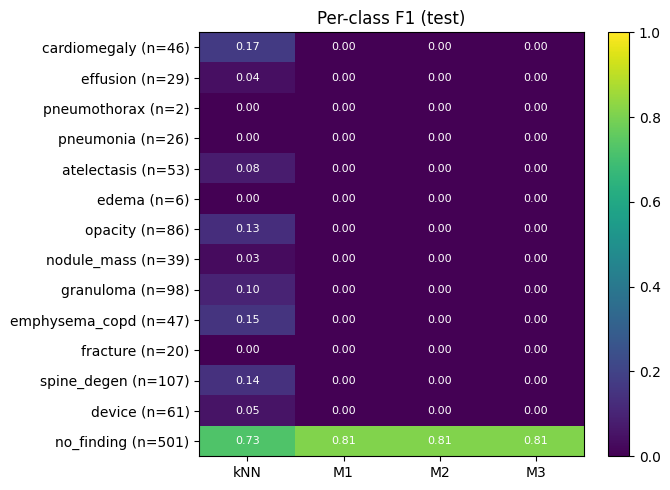

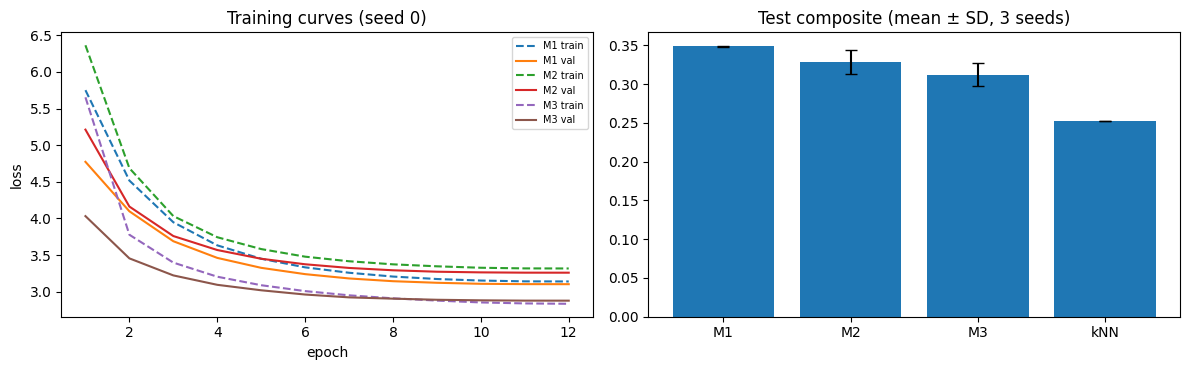

In [19]:
# ---- per-class results (test, mean F1 over seeds) ----
final_runs = [r for r in load_runs() if r['stage'] == 'final' and r['epochs'] == CFG['EPOCHS']]
pc = {k: pd.DataFrame([{l: r['metrics_test']['per_class'][l]['f1'] for l in LABELS} for r in final_runs if r['name'] == k]).mean() for k in ['M1', 'M2', 'M3']}
pc['kNN'] = pd.Series({l: BASE['B1 kNN retrieval (PCA)']['test']['per_class'][l]['f1'] for l in LABELS})
support = {l: BASE['B1 kNN retrieval (PCA)']['test']['per_class'][l]['support'] for l in LABELS}
pct = pd.DataFrame(pc); pct.insert(0, 'support', pd.Series(support)); TABLES['per_class_f1_test'] = pct
print('Per-class CE F1 on test (mean of 3 seeds) — support = #test reports with that finding'); display(pct.round(3))
fig, ax = plt.subplots(figsize=(7, 5)); im = ax.imshow(pct[['kNN', 'M1', 'M2', 'M3']].values, cmap='viridis', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(4)); ax.set_xticklabels(['kNN', 'M1', 'M2', 'M3']); ax.set_yticks(range(K)); ax.set_yticklabels([f'{l} (n={support[l]})' for l in LABELS])
for i in range(K):
    for j in range(4): ax.text(j, i, f"{pct[['kNN','M1','M2','M3']].values[i, j]:.2f}", ha='center', va='center', color='w', fontsize=8)
plt.colorbar(im); plt.title('Per-class F1 (test)'); plt.tight_layout(); plt.show()

# ---- training curves + bar chart ----
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for r in final_runs:
    if r['seed'] == 0:
        h = pd.DataFrame(r['history']); ax[0].plot(h.epoch, h.train_loss, '--', label=f"{r['name']} train"); ax[0].plot(h.epoch, h.val_loss, label=f"{r['name']} val")
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss'); ax[0].legend(fontsize=7); ax[0].set_title('Training curves (seed 0)')
names = ['M1', 'M2', 'M3']; mu = [TEST[TEST.name == n].composite.mean() for n in names]; sd = [TEST[TEST.name == n].composite.std(ddof=1) for n in names]
ax[1].bar(names + ['kNN'], mu + [BASE['B1 kNN retrieval (PCA)']['test']['composite']], yerr=sd + [0], capsize=4); ax[1].set_title('Test composite (mean ± SD, 3 seeds)'); plt.tight_layout(); plt.show()

## 13. Model Comparison, Confidence Intervals and Hypothesis Verdicts (Requirements 6 & 9)
* **Bootstrap 95 % CI** (200 resamples of the test set, seed-0 predictions) for BLEU-4 and ROUGE-L.
* **Verdicts:** for each hypothesis we compare seed-level scores with Welch's t-test. With only 3 seeds the test has little power, so we label a hypothesis **Supported** when the mean difference is positive *and* p < 0.10, **Weak evidence** if positive but p ≥ 0.10, and **Rejected** otherwise. Discuss this honestly in the report.

In [20]:
from scipy import stats
def boot_ci(refs, hyps, n=200, seed=0):
    rg = np.random.RandomState(seed); N = len(refs); rls = np.array([rouge_l(r, h) for r, h in zip(refs, hyps)]); b4, rl = [], []
    for _ in range(n):
        ix = rg.randint(0, N, N); b4.append(bleu_all([refs[i] for i in ix], [hyps[i] for i in ix])[3]); rl.append(rls[ix].mean())
    f = lambda a: f'[{np.percentile(a, 2.5):.3f}, {np.percentile(a, 97.5):.3f}]'; return f(b4), f(rl)

def get_hyps(name, seed=0, split='test'):
    r = [x for x in load_runs() if x['name'] == name and x['seed'] == seed and x['epochs'] == CFG['EPOCHS'] and x['stage'] != 'tune'][0]
    return json.load(open(r['preds'][split]))
rows = []
for nm, h in [('B1 kNN retrieval', BASE['B1 kNN retrieval (PCA)']['hyps'])] + [(NICE[k], get_hyps(k)) for k in ['M1', 'M2', 'M3']]:
    a, b = boot_ci(REFS['test'], h); mm = compute_metrics(REFS['test'], h); rows.append({'Model': nm, 'BLEU-4': round(mm['bleu4'], 3), 'BLEU-4 95% CI': a, 'ROUGE-L': round(mm['rougeL'], 3), 'ROUGE-L 95% CI': b})
TABLES['bootstrap_ci_test'] = pd.DataFrame(rows); display(TABLES['bootstrap_ci_test'])

def compare(a, b, metric):
    A, B = TEST[TEST.name == a][metric].values, TEST[TEST.name == b][metric].values
    if len(A) < 2 or len(B) < 2: return None
    p = stats.ttest_ind(A, B, equal_var=False).pvalue; p = 1.0 if np.isnan(p) else p
    return dict(pair=f'{a} vs {b}', metric=HEAD[metric], diff=A.mean() - B.mean(), p=p)
HYP = [('H1 pretraining helps (CNN)', [('M1', 'M1_scratch', 'composite')]), ('H1 pretraining helps (ViT)', [('M2', 'M2_scratch', 'composite')]),
       ('H2 ViT-Transformer > CNN-LSTM', [('M2', 'M1', 'composite'), ('M2', 'M1', 'rougeL'), ('M2', 'M1', 'ce_macro_f1')]),
       ('H3 multi-view+tags improve CE-F1', [('M3', 'M2', 'ce_macro_f1'), ('M3', 'M2', 'ce_micro_f1')]),
       ('H3b … more than they improve BLEU-4', [('M3', 'M2', 'bleu4')]),
       ('H4 augmentation helps', [('M2', 'M2_noaug', 'composite')])]
vr = []
for h, pairs in HYP:
    cs = [c for c in (compare(*p) for p in pairs) if c]
    if not cs: continue
    verdict = 'Supported' if all(c['diff'] > 0 and c['p'] < 0.10 for c in cs) else ('Weak evidence' if all(c['diff'] > 0 for c in cs) else 'Rejected / not supported')
    vr.append({'Hypothesis': h, 'Comparisons': '; '.join(f"{c['pair']} [{c['metric']}] Δ={c['diff']:+.3f} (p={c['p']:.2f})" for c in cs), 'Verdict': verdict})
TABLES['hypothesis_verdicts'] = pd.DataFrame(vr); pd.set_option('display.max_colwidth', 200); display(TABLES['hypothesis_verdicts'])
print('Note: H3b compares the BLEU-4 gain with the CE gain above. Compare the sizes of the gains and discuss in the report.')

print('\nPretrained vs scratch / augmentation (test, mean ± SD):'); display(result_table(['M1', 'M1_scratch', 'M2', 'M2_scratch', 'M2_noaug'], TEST))

,Model,BLEU-4,BLEU-4 95% CI,ROUGE-L,ROUGE-L 95% CI
0,B1 kNN retrieval,0.092,"[0.083, 0.101]",0.280,"[0.273, 0.287]"
1,M1 CNN-LSTM (classic),0.128,"[0.121, 0.136]",0.380,"[0.370, 0.387]"
2,M2 ViT-Transformer (modern),0.123,"[0.114, 0.129]",0.369,"[0.361, 0.377]"
3,M3 Multi-view Tag-guided (advanced),0.064,"[0.058, 0.072]",0.306,"[0.297, 0.315]"


,Hypothesis,Comparisons,Verdict
0,H1 pretraining helps (CNN),M1 vs M1_scratch [Composite] Δ=+0.007 (p=0.05),Supported
1,H1 pretraining helps (ViT),M2 vs M2_scratch [Composite] Δ=+0.002 (p=0.91),Weak evidence
2,H2 ViT-Transformer > CNN-LSTM,M2 vs M1 [Composite] Δ=-0.020 (p=0.15); M2 vs M1 [ROUGE-L] Δ=-0.033 (p=0.13); M2 vs M1 [CE macro-F1] Δ=+0.000 (p=1.00),Rejected / not supported
3,H3 multi-view+tags improve CE-F1,M3 vs M2 [CE macro-F1] Δ=+0.000 (p=1.00); M3 vs M2 [CE micro-F1] Δ=+0.000 (p=1.00),Rejected / not supported
4,H3b … more than they improve BLEU-4,M3 vs M2 [BLEU-4] Δ=-0.025 (p=0.22),Rejected / not supported
5,H4 augmentation helps,M2 vs M2_noaug [Composite] Δ=+0.001 (p=0.96),Weak evidence


Note: H3b compares the BLEU-4 gain with the CE gain above. Compare the sizes of the gains and discuss in the report.

Pretrained vs scratch / augmentation (test, mean ± SD):


,Model,#seeds,BLEU-1,BLEU-4,ROUGE-L,CE micro-F1,CE macro-F1,Composite
0,M1,3,0.380 ± 0.007,0.126 ± 0.004,0.379 ± 0.002,0.540 ± 0.000,0.058 ± 0.000,0.349 ± 0.001
1,M1_scratch,3,0.354 ± 0.012,0.115 ± 0.003,0.370 ± 0.007,0.540 ± 0.000,0.058 ± 0.000,0.342 ± 0.003
2,M2,3,0.274 ± 0.075,0.099 ± 0.023,0.346 ± 0.023,0.540 ± 0.000,0.058 ± 0.000,0.328 ± 0.015
3,M2_scratch,3,0.259 ± 0.081,0.090 ± 0.033,0.350 ± 0.026,0.540 ± 0.000,0.058 ± 0.000,0.327 ± 0.019
4,M2_noaug,3,0.273 ± 0.074,0.098 ± 0.021,0.345 ± 0.022,0.540 ± 0.000,0.058 ± 0.000,0.328 ± 0.014


## 14. Ablation Study — Table 5 (Requirement 8)
Starting from the full M3, remove one component at a time and measure the change.

In [21]:
def delta_table(full, variants, labels):
    rows = []
    for v, lab in zip([full] + variants, ['Full model'] + labels):
        d = TEST[TEST.name == v]
        if d.empty: continue
        row = {'Component removed': lab, 'BLEU-4': ms(d, 'bleu4'), 'ROUGE-L': ms(d, 'rougeL'), 'CE macro-F1': ms(d, 'ce_macro_f1'), 'Composite': ms(d, 'composite')}
        for c, h in [('bleu4', 'Δ BLEU-4'), ('rougeL', 'Δ ROUGE-L'), ('ce_macro_f1', 'Δ CE macro-F1')]: row[h] = f'{d[c].mean() - TEST[TEST.name == full][c].mean():+.3f}'
        rows.append(row)
    return pd.DataFrame(rows)
t5 = pd.concat([delta_table('M3', ['M3_nolat', 'M3_notags'], ['– lateral view (frontal only)', '– tag module (aux head + tag tokens)']),
                delta_table('M2', ['M2_scratch', 'M2_noaug'], ['– pretraining (M2, scratch)', '– augmentation (M2)']).iloc[1:]], ignore_index=True)
TABLES['table5_ablation'] = t5; print('TABLE 5 — Ablation (test set; Δ vs the corresponding full model)'); display(t5)

TABLE 5 — Ablation (test set; Δ vs the corresponding full model)


,Component removed,BLEU-4,ROUGE-L,CE macro-F1,Composite,Δ BLEU-4,Δ ROUGE-L,Δ CE macro-F1
0,Full model,0.075 ± 0.018,0.322 ± 0.028,0.058 ± 0.000,0.312 ± 0.015,+0.000,+0.000,+0.000
1,– lateral view (frontal only),0.065 ± 0.001,0.306 ± 0.000,0.058 ± 0.000,0.303 ± 0.000,-0.010,-0.016,+0.000
2,– tag module (aux head + tag tokens),0.088 ± 0.041,0.325 ± 0.033,0.058 ± 0.000,0.318 ± 0.025,+0.013,+0.003,+0.000
3,"– pretraining (M2, scratch)",0.090 ± 0.033,0.350 ± 0.026,0.058 ± 0.000,0.327 ± 0.019,-0.009,+0.004,+0.000
4,– augmentation (M2),0.098 ± 0.021,0.345 ± 0.022,0.058 ± 0.000,0.328 ± 0.014,-0.002,-0.000,+0.000


## 15. Error Analysis — Table 6 (Requirement 10)
We analyse the model with the best **validation** composite score (seed 0) on the test set. Each test report is assigned to exactly one error type by comparing the labeler's findings in the generated vs. the reference report.

Best model by validation composite: M1
TABLE 6 — Error analysis


,Error type,Count,Share,Example (test idx),Likely cause
0,Good match,340,46.3%,149,—
1,Missed abnormality (says normal),233,31.7%,361,class imbalance: ~40 % normal reports → model defaults to the normal template; subtle finding
2,"Clinically consistent, wording differs",161,21.9%,73,metric limitation: n-gram metrics penalise valid paraphrases


,support,missed (FN),spurious (FP)
cardiomegaly,46,46,0
effusion,29,29,0
pneumothorax,2,2,0
pneumonia,26,26,0
atelectasis,53,53,0
edema,6,6,0
opacity,86,86,0
nodule_mass,39,39,0
granuloma,98,98,0
emphysema_copd,47,47,0


Mean ROUGE-L by lateral availability / reference length:


has_lat,False,True
rouge,0.37,0.381


len_bin,"(0, 20]","(20, 40]","(40, 61]"
mean,0.412,0.406,0.31
count,113.000,414.000,207.00


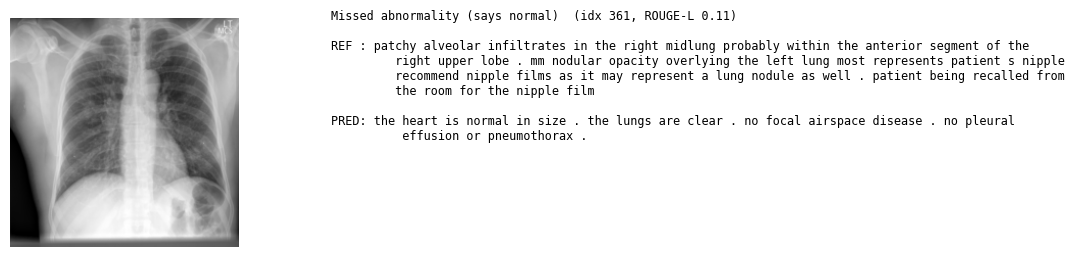

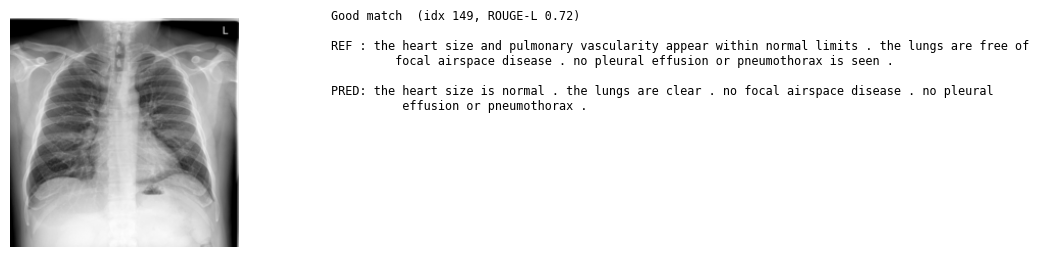

In [22]:
best_name = VAL[VAL.name.isin(['M1', 'M2', 'M3'])].groupby('name').composite.mean().idxmax(); print('Best model by validation composite:', best_name)
hyps = get_hyps(best_name); refs = REFS['test']
Yr = np.stack([label_vec(t) for t in refs]); Yh = np.stack([label_vec(t) for t in hyps]); rl = np.array([rouge_l(r, h) for r, h in zip(refs, hyps)])

def categorize(i):
    toks = hyps[i].split(); r, h = Yr[i][CORE_IDX] > 0, Yh[i][CORE_IDX] > 0
    if len(toks) < 4 or (len(toks) > 8 and len(set(toks)) / len(toks) < 0.3): return 'Degenerate / repetitive text'
    fn, fp = (r & ~h).any(), (h & ~r).any()
    if fn and fp: return 'Wrong abnormality (missed + spurious)'
    if fn: return 'Missed abnormality (says normal)' if not h.any() else 'Partially missed abnormality'
    if fp: return 'Hallucinated abnormality'
    return 'Clinically consistent, wording differs' if rl[i] < 0.35 else 'Good match'
cat = np.array([categorize(i) for i in range(len(refs))])
CAUSE = {'Degenerate / repetitive text': 'greedy decoding collapse, weak language modelling',
         'Wrong abnormality (missed + spurious)': 'visual confusion between similar findings (opacity vs consolidation vs effusion)',
         'Missed abnormality (says normal)': 'class imbalance: ~40 % normal reports → model defaults to the normal template; subtle finding',
         'Partially missed abnormality': 'rare/co-occurring findings under-represented in training',
         'Hallucinated abnormality': 'language prior / dataset bias, over-prediction of common findings',
         'Clinically consistent, wording differs': 'metric limitation: n-gram metrics penalise valid paraphrases',
         'Good match': '—'}
rows = []
for c in pd.Series(cat).value_counts().index:
    ix = np.where(cat == c)[0]; ex = ix[np.argmin(rl[ix])] if c != 'Good match' else ix[np.argmax(rl[ix])]
    rows.append({'Error type': c, 'Count': len(ix), 'Share': f'{100*len(ix)/len(cat):.1f}%', 'Example (test idx)': int(ex), 'Likely cause': CAUSE[c]})
t6 = pd.DataFrame(rows); TABLES['table6_error_analysis'] = t6; print('TABLE 6 — Error analysis'); display(t6)

# per-class FN / FP counts
fnfp = pd.DataFrame({'support': Yr.sum(0), 'missed (FN)': ((Yr > 0) & (Yh == 0)).sum(0), 'spurious (FP)': ((Yh > 0) & (Yr == 0)).sum(0)}, index=LABELS); display(fnfp.astype(int))
# effect of lateral view availability and reference length
te = parts['test'].reset_index(drop=True); te['rouge'] = rl; te['has_lat'] = te.lateral.notna(); te['len_bin'] = pd.cut(te.ref.str.split().str.len(), [0, 20, 40, 61])
print('Mean ROUGE-L by lateral availability / reference length:'); display(te.groupby('has_lat').rouge.mean().round(3).to_frame().T); display(te.groupby('len_bin').rouge.agg(['mean', 'count']).round(3).T)

# concrete examples with images
def show(i, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={'width_ratios': [1, 3]}); ax[0].imshow(IMGS[F2I[te.frontal[i]]], cmap='gray'); ax[0].axis('off')
    ax[1].axis('off'); ax[1].text(0, 1, f'{title}  (idx {i}, ROUGE-L {rl[i]:.2f})\n\nREF : ' + '\n         '.join(re.findall(r'.{1,95}(?:\s|$)', refs[i])) + '\n\nPRED: ' + '\n          '.join(re.findall(r'.{1,95}(?:\s|$)', hyps[i])), va='top', fontsize=8.5, family='monospace'); plt.show()
for c in ['Missed abnormality (says normal)', 'Hallucinated abnormality', 'Wrong abnormality (missed + spurious)', 'Good match']:
    ix = np.where(cat == c)[0]
    if len(ix): show(int(ix[np.argmin(rl[ix])] if c != 'Good match' else ix[np.argmax(rl[ix])]), c)

## 16. Computational Cost — Table 7 (Requirement 11)
Training time and peak GPU memory come from training; inference time is the average generation time per image on the test set (batch 32, fp16); model size is the saved checkpoint.

In [23]:
rows = []
for k in ['M1', 'M2', 'M3']:
    d = TEST[TEST.name == k]
    rows.append({'Model': NICE[k], 'Parameters': f'{d.params.iloc[0]/1e6:.1f}M', 'Size (MB, ckpt)': f'{d.ckpt_mb.dropna().iloc[0]:.0f}' if d.ckpt_mb.notna().any() else 'n/a',
                 'Train time / run (min)': f'{d.train_time.mean()/60:.1f} ± {d.train_time.std(ddof=1)/60:.1f}', 'Epochs run': f'{d.epochs_run.mean():.1f}',
                 'Inference (ms/img)': f'{d.infer_ms.mean():.1f}', 'Peak GPU mem (MB)': f'{d.peak_mem.mean():.0f}', 'Hardware': HW})
for k, v in BASE.items():
    rows.append({'Model': k, 'Parameters': '–', 'Size (MB, ckpt)': '–', 'Train time / run (min)': f"{v['fit_s']/60:.2f}", 'Epochs run': '–', 'Inference (ms/img)': f"{v['test']['infer_ms']:.2f}", 'Peak GPU mem (MB)': '0', 'Hardware': 'CPU'})
t7 = pd.DataFrame(rows); TABLES['table7_cost'] = t7; print('TABLE 7 — Computational cost'); display(t7)

TABLE 7 — Computational cost


,Model,Parameters,"Size (MB, ckpt)",Train time / run (min),Epochs run,Inference (ms/img),Peak GPU mem (MB),Hardware
0,M1 CNN-LSTM (classic),15.5M,59,4.9 ± 0.1,12.0,2.2,878,Tesla T4
1,M2 ViT-Transformer (modern),25.4M,97,3.6 ± 0.0,12.0,5.0,1670,Tesla T4
2,M3 Multi-view Tag-guided (advanced),25.4M,97,4.2 ± 0.0,12.0,5.7,2835,Tesla T4
3,B0 Generic report,–,–,0.08,–,0.00,0,CPU
4,B1 kNN retrieval (PCA),–,–,0.07,–,0.44,0,CPU


## 17. Live Demo (Requirement 12) — Gradio
Uploads a frontal X-ray (and optionally a lateral view) and returns the generated report plus detected findings. The demo loads the best model by validation score from the seed-0 checkpoint. It runs inside Colab with a public share link — launch it during the presentation.
> ⚠️ Educational prototype only — not for clinical use.

In [24]:
import gradio as gr
dm = best_name; assert (CKPT / f'{dm}__s0.pt').exists(), 'checkpoint missing — run §10 first'
demo_model = build_model(SPECS[dm]).to(DEVICE); demo_model.load_state_dict(torch.load(CKPT / f'{dm}__s0.pt', map_location=DEVICE)); demo_model.eval()
json.dump({'itos': tok.itos, 'model': dm, 'spec': SPECS[dm], 'labels': LABELS}, open(CKPT / 'demo_bundle.json', 'w'))

def _to_tensor(im):
    x = np.array(im.convert('L').resize((S, S), Image.BILINEAR), dtype=np.uint8); return torch.from_numpy(x).unsqueeze(0).expand(3, -1, -1).contiguous()
@torch.no_grad()
def predict(frontal, lateral=None):
    if frontal is None: return 'Please upload a frontal chest X-ray.', {}
    f = _to_tensor(frontal); has = lateral is not None; l = _to_tensor(lateral) if has else f.clone()
    b = prep((f[None], l[None], torch.tensor([float(has)]), torch.zeros(1, 2, dtype=torch.long), torch.zeros(1, K), torch.zeros(1, dtype=torch.long)))
    with AC(): ids = demo_model.generate(b, MAX_LEN + 1); text = tok.decode(ids[0].cpu())
    v = label_vec(text); tags = {l_: 1.0 for l_, x in zip(LABELS, v) if x} or {'no_finding': 1.0}
    if getattr(demo_model, 'use_tags', False):                                    # M3: show the tag head's probabilities
        with AC(): _, _, lg = demo_model.memory(b)
        tags = {l_: float(p) for l_, p in zip(LABELS, torch.sigmoid(lg.float())[0].cpu())}
    return text.replace(' .', '.').capitalize(), tags

ex_dir = Path('/content/demo_examples'); ex_dir.mkdir(exist_ok=True); examples = []
for i in range(min(3, len(te))):
    p = ex_dir / f'example_{i}.png'; Image.fromarray(IMGS[F2I[te.frontal[i]]].numpy()).save(p); examples.append([str(p), None])
app = gr.Interface(fn=predict, inputs=[gr.Image(type='pil', label='Frontal chest X-ray'), gr.Image(type='pil', label='Lateral view (optional)')],
                   outputs=[gr.Textbox(label='Generated report', lines=5), gr.Label(num_top_classes=6, label='Findings')], examples=examples,
                   title=f'Chest X-ray Report Generation ({NICE[dm]})', description='Educational prototype (IU X-Ray). Not for clinical use.')
app.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e5b7b7a04f0754e963.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 18. Export — Repository Skeleton, README, Dataset Documentation, Tables (Deliverables 1, 2, 4, 11, 12)
Creates the folder layout required by the course (`configs/`, `experiments/`, `checkpoints/`, `demo/`, `report/`, `contributions/`) inside your project folder and writes the result tables, configs, README and dataset documentation.
*Tip:* for the Git repository, also split the notebook code into `src/datasets`, `src/models`, `train.py`, `evaluate.py` (the notebook sections are already organised in that order) and push to GitHub with the TAs as collaborators.

In [25]:
for d in ['configs', 'data', 'src/datasets', 'src/models', 'experiments', 'checkpoints', 'demo', 'report', 'contributions']: (ROOT / d).mkdir(parents=True, exist_ok=True)
for n, t in TABLES.items(): t.to_csv(RES / f'{n}.csv', index=True if n == 'per_class_f1_test' else False)
for k, sp in SPECS.items(): json.dump(dict(spec=sp, lr=BEST_LR.get(k), **CFG), open(ROOT / 'configs' / f'{k}.json', 'w'), indent=2)
pd.DataFrame(columns=['Week', 'Task', 'Hours', 'Evidence (commits, runs, report sections)', 'Problems', 'Co-signed by']).to_csv(ROOT / 'contributions' / 'log_template.csv', index=False)
bm = TEST[TEST.name == best_name]
(ROOT / 'requirements.txt').write_text('torch\ntorchvision\ntimm\nnltk\nscikit-learn\nscipy\npandas\nnumpy\nmatplotlib\npillow\ngradio\nkaggle\n')
(ROOT / 'DATASET.md').write_text(f"""# Dataset documentation
* **Name:** IU X-Ray (Open-i, Indiana University / NLM) - {len(df)} studies, frontal + lateral chest X-ray PNGs + radiology reports.
* **Source:** Kaggle mirror `raddar/chest-xrays-indiana-university`; original: https://openi.nlm.nih.gov/ ; Demner-Fushman et al., JAMIA 2016.
* **Licence:** Open-i / NLM terms for research use - verify on the original site.
* **Text preprocessing:** findings (fallback impression), lower-case, removal of `XXXX` anonymisation tokens and numbers, word+period tokenisation, truncation to {MAX_LEN} tokens, vocabulary (min freq {CFG['MIN_FREQ']}, size {V}) built on the training split only.
* **Image preprocessing:** grayscale, resize {S}x{S}, replicate to 3 channels, ImageNet normalisation. Train augmentation: affine (±7°, 5% shift, 0.9-1.1 scale) + brightness/contrast 0.2; no flipping.
* **Split:** random by study uid with seed {CFG['SPLIT_SEED']}: 70/10/20 -> train {len(parts['train'])}, val {len(parts['val'])}, test {len(parts['test'])}; asserted no uid/image overlap; test used only for final evaluation. Limitation: no patient id available.
* **Labels:** 14 finding labels from our own negation-aware rule-based labeler (used for auxiliary supervision and clinical-efficacy metric).
""")
(ROOT / 'README.md').write_text(f"""# Chest X-ray Report Generation (Deep Learning AI403 - Final Project)
**Team:** <team name + members>  |  **Idea:** #8 Chest X-ray report generation (Image -> text)

**Task:** generate the findings section of a radiology report from chest X-ray image(s).
**Best result (test):** {NICE.get(best_name, best_name)} - BLEU-4 {bm.bleu4.mean():.3f}, ROUGE-L {bm.rougeL.mean():.3f}, CE micro-F1 {bm.ce_micro_f1.mean():.3f} (mean of {len(bm)} seeds).

## Environment
Google Colab (T4 GPU). `pip install -r requirements.txt`
## Dataset
Kaggle API token -> `kaggle datasets download -d raddar/chest-xrays-indiana-university --unzip` (done inside the notebook, section 2). See DATASET.md.
## Training / evaluation / demo
Run the notebook top-to-bottom: section 9 (hyper-parameter study), 10 (final 3-seed training: M1, M2, M3), 11 (studies & ablations), 12-16 (evaluation, tables), 17 (Gradio demo).
## Hardware & runtimes
{HW}. Per-run training times are in experiments/table7_cost.csv.
## Credits
IU X-Ray dataset (Demner-Fushman 2016); timm ViT-S/16 weights; torchvision ResNet-18 weights; NLTK BLEU; scikit-learn. Own code: attention, Transformer decoder, Bahdanau attention, decoder, ROUGE-L, labeler.
""")
print('Exported to', ROOT); print(sorted(p.name for p in ROOT.iterdir()))

Exported to /content/cxr_report_project
['DATASET.md', 'README.md', 'checkpoints', 'configs', 'contributions', 'data', 'demo', 'experiments', 'report', 'requirements.txt', 'src']


## 19. References & Credits (Requirement 13 — no external AI APIs were used for predictions)
1. Demner-Fushman et al., *Preparing a collection of radiology examinations for distribution and retrieval*, JAMIA 2016 (IU X-Ray / Open-i).
2. Vaswani et al., *Attention Is All You Need*, NeurIPS 2017 (Transformer, multi-head attention).
3. Dosovitskiy et al., *An Image is Worth 16×16 Words*, ICLR 2021 (ViT); Wightman, *PyTorch Image Models (timm)*.
4. He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016 (ResNet).
5. Bahdanau et al., *Neural Machine Translation by Jointly Learning to Align and Translate*, ICLR 2015; Xu et al., *Show, Attend and Tell*, ICML 2015.
6. Chen et al., *Generating Radiology Reports via Memory-driven Transformer (R2Gen)*, EMNLP 2020; Wang et al., *TieNet*, CVPR 2018 (tag/label-aided report generation).
7. Irvin et al., *CheXpert*, AAAI 2019 (labeler idea behind clinical-efficacy metrics).
8. Papineni et al., *BLEU*, ACL 2002; Lin, *ROUGE*, 2004; Chen & Cherry, *A systematic comparison of smoothing techniques for sentence-level BLEU*, 2014.
9. Loshchilov & Hutter, *Decoupled Weight Decay Regularization (AdamW)*, ICLR 2019; Szegedy et al., 2016 (label smoothing); Paulus et al., 2018 (n-gram blocking).
10. Kaggle dataset mirror: `raddar/chest-xrays-indiana-university`.

**Limitations to discuss in the report:** small dataset, no patient-level split info, greedy decoding (no beam search), rule-based labeler is not CheXpert-grade, 3 seeds only (low statistical power), reports reflect a single institution, not for clinical use.
**Ethical considerations:** de-identified public data; risk of hallucinated findings / automation bias; fairness across demographics not measurable with this data; clinical use would need validation and radiologist oversight.

## 20. Viva Cheat-sheet (Requirement 14) — be ready to explain
* **Why not accuracy?** The output is free text; we use n-gram metrics (BLEU/ROUGE) *and* clinical-efficacy F1, because a fluent report can still miss or invent a disease.
* **Leakage:** split by study; both views stay together; vocabulary and PCA/kNN fitted on train only; test never used for tuning (code `assert`).
* **Why three families?** M1 shows the classic encoder–decoder with attention, M2 replaces both parts with Transformers, M3 adds domain knowledge (lateral view + disease tags).
* **What we wrote ourselves:** `MHA` (scaled dot-product attention with causal & padding masks), `DecLayer`/`TDecoder`, Bahdanau attention + LSTM loop, tag-token module, greedy decoder with n-gram blocking, ROUGE-L, the rule-based labeler.
* **Why 3 seeds & Welch test?** To show variance; with n=3 power is low, hence the three-level verdict.
* **Why no horizontal-flip augmentation?** Left/right matters (heart, effusion side) — flipping would create wrong labels.
* **Main failure mode:** normal-template bias from class imbalance → missed abnormalities (see Table 6).
* **Ablation reading:** a component matters if removing it lowers the metric by more than the seed SD.